In [1]:
import os, sys, pathlib
from pathlib import Path

ROOT = Path.cwd().resolve().parent          # analysis/ -> FitNMF/
# or, to work from any subfolder: ROOT = find_repo_root()   (function from before)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import re
import json
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from joblib import Parallel, delayed, parallel_backend
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from scipy.stats import betabinom, nbinom
from venn import venn

from src.model import joint_soft_dynamics_nmf
from src.helpers import binarize_signature_matrix, _parse_dates
from src.nmf_update_fitness import compute_p
from evaluation.plot_joint_matched_heatmap import plot_matched_heatmap_and_abundances
from evaluation.plot_binariness import plot_binariness

In [2]:
"""
Simulate the mutational SIGNATURE matrix W for two variants -- just the
signature part (no H(t) simulation; combine with your own abundances via
y_m(t) = W[m,:] @ H[:,t] once you have both).

W (variant signatures): which mutations each variant carries. Static,
binary, hard-assigned -- a mutation is either present or absent in a given
variant. Per your Discussion assumption, a single mutation is allowed to be
present in MULTIPLE variants (shared/homoplasic mutations), so columns of W
are not required to be disjoint -- this builds three categories of sites
(private-to-A, private-to-B, shared-by-both) to make that concrete.

Outputs: simulate_variant_signatures.png (and .pdf), simulated_variant_signatures.csv
"""


def simulate_variant_signatures(n_positions=40, n_private_A=12, n_private_B=12,
                                 n_shared=6, seed=42):
    """
    Binary signature matrix W (n_positions x 2) for variants A and B.

    Returns
    -------
    W        : (n_positions, 2) int ndarray, columns = [A, B]
    category : (n_positions,) object ndarray -- one of
               'private_A', 'private_B', 'shared', 'none' per site
    order    : index order (private_A, shared, private_B, none) useful for
               a grouped heatmap/plot
    """
    rng = np.random.default_rng(seed)
    assert n_shared + n_private_A + n_private_B <= n_positions, \
        "n_shared + n_private_A + n_private_B must not exceed n_positions"

    perm = rng.permutation(n_positions)
    shared_idx = perm[:n_shared]
    private_A_idx = perm[n_shared:n_shared + n_private_A]
    private_B_idx = perm[n_shared + n_private_A: n_shared + n_private_A + n_private_B]
    none_idx = perm[n_shared + n_private_A + n_private_B:]

    W = np.zeros((n_positions, 2), dtype=int)
    W[private_A_idx, 0] = 1
    W[private_B_idx, 1] = 1
    W[shared_idx, 0] = 1
    W[shared_idx, 1] = 1

    category = np.array(['none'] * n_positions, dtype=object)
    category[private_A_idx] = 'private_A'
    category[private_B_idx] = 'private_B'
    category[shared_idx] = 'shared'

    order = np.concatenate([private_A_idx, shared_idx, private_B_idx, none_idx])
    return W, category, order


def plot_signature_matrix(W, category, order, out_stem='simulate_variant_signatures'):
    n_private_A = int((category == 'private_A').sum())
    n_shared = int((category == 'shared').sum())
    n_private_B = int((category == 'private_B').sum())

    fig, ax = plt.subplots(figsize=(4, 5.5))
    ax.imshow(W[order], aspect='auto', cmap='Greys', vmin=0, vmax=1)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Variant A', 'Variant B'])
    ax.set_ylabel('Mutation site (grouped by category)')
    ax.axhline(n_private_A - 0.5, color='C3', lw=1)
    ax.axhline(n_private_A + n_shared - 0.5, color='C3', lw=1)
    ax.text(1.55, n_private_A / 2, 'private A', va='center', fontsize=8, color='C1')
    ax.text(1.55, n_private_A + n_shared / 2, 'shared', va='center', fontsize=8, color='C2')
    ax.text(1.55, n_private_A + n_shared + n_private_B / 2, 'private B',
            va='center', fontsize=8, color='C0')
    ax.set_title('Binary signature matrix $W$\n(1 = mutation present)')
    fig.tight_layout()
    fig.savefig(f'{out_stem}.png', dpi=180, bbox_inches='tight')
    fig.savefig(f'{out_stem}.pdf', bbox_inches='tight')
    plt.close(fig)
    return fig


if __name__ == '__main__':
    W, category, order = simulate_variant_signatures()

    sig_df = pd.DataFrame({'position': np.arange(1, len(W) + 1),
                            'W_A': W[:, 0], 'W_B': W[:, 1], 'category': category})
    # Uncomment to save the simulated signature matrix to CSV

    # sig_df.to_csv('simulated_variant_signatures.csv', index=False)
    print(sig_df.groupby('category').size())

    # plot_signature_matrix(W, category, order)
    # print('Saved simulate_variant_signatures.png/.pdf and simulated_variant_signatures.csv')


category
none         10
private_A    12
private_B    12
shared        6
dtype: int64


In [3]:
mpl.rcParams.update({
    'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'legend.fontsize': 9, 'lines.linewidth': 2.0, 'savefig.dpi': 300,
    'figure.dpi': 120, 'pdf.fonttype': 42,
    'font.family': 'sans-serif', 'font.sans-serif': ['DejaVu Sans', 'Arial'],
})




def simulate_neutral_drift_abundances(s=0.0, p0=0.15, Ne=200, g=4,
                                      t0='2021-11-01', t1='2022-06-01', seed=42, return_raw=False):
    """Two-variant Wright-Fisher drift.

      s            : per-day log-fitness advantage of B (0 = pure neutral drift)
      p0           : initial frequency of B
      Ne           : effective population size (integer)
      g            : generation time in days (integer). One binomial step per g days,
                     linearly interpolated to daily values (g=1 -> one step per day).

    """
    dates = pd.date_range(pd.Timestamp(t0), pd.Timestamp(t1), freq='D')
    n = len(dates)
    rng = np.random.default_rng(seed)
    w_B = np.exp(s * g)                                    # selection acting over one generation

    gen_idx = list(range(0, n, int(g)))
    if gen_idx[-1] != n - 1:
        gen_idx.append(n - 1)
    p = np.empty(len(gen_idx)); p[0] = p0
    for k in range(1, len(gen_idx)):
        q = p[k - 1]
        p_sel = w_B * q / ((1.0 - q) + q * w_B)            # selection (absent when s = 0)
        p[k] = rng.binomial(int(Ne), p_sel) / Ne           # binomial sampling = genetic drift
    p_raw = np.interp(np.arange(n, dtype=float), np.array(gen_idx, float), p)

    p_B = p_raw
    out = (dates, 1.0 - p_B, p_B)
    return out + (p_raw,) if return_raw else out




In [4]:
"""
Multiply the two-variant signature matrix W (simulate_variant_signatures.py)
by GENETIC-DRIFT abundance trajectories p_A(t)/p_B(t) to get the per-mutation
frequency matrix
"""

if __name__ == '__main__':
    # ---- ONE place to set the genetic-drift parameters ----
    # p0 MUST be > 0 (a variant at 0 is a fixed point and never moves);
    # k_disp ~ 0.1-1 (0.0009 would give N_e < 1); s small => near-neutral.

    # ---- signatures W ----
    W, category, order = simulate_variant_signatures()

    # ---- abundances H from genetic drift (imported, single source of truth) ----
    dates, p_A, p_B = simulate_neutral_drift_abundances(
    s=0.00, p0=0.25, Ne=500, g=3, seed=42)

    #dates, p_A, p_B = simulate_quadratic_logit()
    H = np.vstack([p_A, p_B])                 # rows [A, B]
    mutation_freq = W @ H


    H = np.vstack([p_A, p_B])  # (2, n_dates), rows [A, B]

    # ---- multiply: mutation_freq[m, t] = W[m, :] @ H[:, t] ----
    mutation_freq = W @ H  # (n_positions, n_dates)


    site_ids = [f'site_{i+1}' for i in range(W.shape[0])]
    date_str = dates.strftime('%Y_%m_%d')
    
    print(f'mutation_freq shape: {mutation_freq.shape} (sites x dates)')
    print(f'p_B: start {p_B[0]:.2f}  min {p_B.min():.2f}  max {p_B.max():.2f}  end {p_B[-1]:.2f}')
    
    # Optional - save the mutation frequency and true H/W matrices to CSV for later use. 
    #print('Saved mutation_freq_from_signatures.csv, true_H_from_signatures.csv, true_W_from_signatures.csv')

    # ---- verification plot: one example site per category ----
    rng = np.random.default_rng(0)
    coverage = 300
    obs_idx = np.arange(0, len(dates), 3)
    obs_dates = dates[obs_idx]


mutation_freq shape: (40, 213) (sites x dates)
p_B: start 0.25  min 0.14  max 0.34  end 0.16


In [5]:
# """Line plot of the true relative abundances H(t) of variants A and B
# (from true_H_from_signatures.csv)."""

# mpl.rcParams.update({'font.size': 11, 'pdf.fonttype': 42, 'font.family': 'sans-serif',
#                      'font.sans-serif': ['DejaVu Sans', 'Arial']})
# H = pd.read_csv('true_H_from_signatures.csv', index_col=0)
# dates = pd.to_datetime(H.index, format='%Y_%m_%d')

# fig, ax = plt.subplots(figsize=(7.5, 4.2))
# ax.plot(dates, H['A'], color='#E8833A', lw=2, label='Variant A')
# ax.plot(dates, H['B'], color='#2F6DB5', lw=2, label='Variant B')
# ax.set_ylim(-0.03, 1.03)
# ax.set_xlabel('Date'); ax.set_ylabel('Relative abundance')
# ax.legend(frameon=False, loc='center right')
# ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
# fig.autofmt_xdate(); fig.tight_layout()
# #fig.savefig('relative_abundances.pdf', bbox_inches='tight')

In [6]:
# ── Noise injection (varies by quality group) ────────────────────────────────────
def simulate_observed(mutation_freq, dates, index,
                       mu, sigma2_depth, gamma,
                       delta, missing_frac, seed=42):
    rng = np.random.default_rng(seed)
    y = (mutation_freq + delta) / (1 + 2 * delta)

    r = mu**2 / (sigma2_depth - mu)
    p = mu / sigma2_depth
    depth = nbinom.rvs(r, p, size=y.shape, random_state=rng)
    depth = np.maximum(depth, 1)

    y_observed = betabinom.rvs(depth, y * (1 - gamma)/gamma, (1 - y)*(1-gamma)/gamma,
                                random_state=rng) / depth
    y_observed_missing = y_observed.copy()
    y_observed_missing[rng.random(y_observed.shape) < missing_frac] = np.nan

    df = pd.DataFrame(y_observed_missing, index=index, columns=dates)
    depth_df = pd.DataFrame(depth, index=index, columns=dates)
    return df, depth_df


# ── Quality tiers: best -> worst ─────────────────────────────────────────────────
gammas = [0.001, 0.01, 0.1]
missing_fracs = [round(m / 10, 2) for m in range(10)] + [0.95]  # 0.0, 0.1, 0.2, ..., 0.9

QUALITY_TIERS = [
    dict(name=f'disp{d_idx+1}_missing_{m_idx+1}',
         mu=6.7e4, sigma2_depth=2.5e10, gamma=gamma, delta=0.0025, missing_frac=mf)
    for d_idx, gamma in enumerate(gammas)
    for m_idx, mf in enumerate(missing_fracs)
]


def build_quality_datasets(X, abundance_matrix, mutation_freq, dates,
                            seed=42, quality_tiers=QUALITY_TIERS):
    """
    Simulate one observed dataset per quality tier from an already-built
    ground truth (X, abundance_matrix, mutation_freq, dates) -- ground
    truth is no longer built inside this function.

    Returns
    -------
    X, abundance_matrix : passed through unchanged (kept in the return
        signature so downstream code doesn't need to track them separately)
    datasets : dict[str, pd.DataFrame]
        quality tier name -> observed mutation-frequency DataFrame (with NaNs)
    """
    datasets = {}
    for tier in quality_tiers:
        df, _depth_df = simulate_observed(
            mutation_freq, dates, X.index,
            mu=tier['mu'], sigma2_depth=tier['sigma2_depth'], gamma=tier['gamma'],
            delta=tier['delta'], missing_frac=tier['missing_frac'],
            seed=seed)
        datasets[tier['name']] = df

    return X, abundance_matrix, datasets


if __name__ == '__main__':
    # X, abundance_matrix, mutation_freq, dates come from
    # simulate_ground_truth_sequential_takeover(...), already computed
    X, abundance_matrix, datasets = build_quality_datasets(pd.DataFrame(W), pd.DataFrame(H), mutation_freq, dates)

    print("Quality datasets summary:")
    for name, df in datasets.items():
        pct_missing = df.isna().mean().mean() * 100
        mean_val = df.stack().mean()
        print(f"  {name}: {pct_missing:5.1f}% missing, mean observed freq = {mean_val:.4f}")

Quality datasets summary:
  disp1_missing_1:   0.0% missing, mean observed freq = 0.4510
  disp1_missing_2:  10.1% missing, mean observed freq = 0.4508
  disp1_missing_3:  20.2% missing, mean observed freq = 0.4520
  disp1_missing_4:  30.1% missing, mean observed freq = 0.4504
  disp1_missing_5:  40.5% missing, mean observed freq = 0.4472
  disp1_missing_6:  50.2% missing, mean observed freq = 0.4483
  disp1_missing_7:  60.3% missing, mean observed freq = 0.4447
  disp1_missing_8:  70.1% missing, mean observed freq = 0.4462
  disp1_missing_9:  79.8% missing, mean observed freq = 0.4462
  disp1_missing_10:  90.0% missing, mean observed freq = 0.4593
  disp1_missing_11:  95.0% missing, mean observed freq = 0.4606
  disp2_missing_1:   0.0% missing, mean observed freq = 0.4492
  disp2_missing_2:  10.2% missing, mean observed freq = 0.4481
  disp2_missing_3:  20.2% missing, mean observed freq = 0.4468
  disp2_missing_4:  30.1% missing, mean observed freq = 0.4474
  disp2_missing_5:  40.6% m

In [7]:
# ---------------------------------------------------------------------
# Publication styling. Set at import so every figure this module makes
# is consistent; override from the caller with mpl.rcParams.update(...)
# before calling if a particular figure needs something different.
# ---------------------------------------------------------------------
mpl.rcParams.update({
    'font.size':             12,
    'axes.labelsize':        14,
    'axes.titlesize':        14,
    'xtick.labelsize':       12,
    'ytick.labelsize':       12,
    'legend.fontsize':       11,
    'axes.linewidth':        1.0,
    'xtick.major.width':     1.0,
    'ytick.major.width':     1.0,
    'savefig.dpi':           300,
    'figure.dpi':            120,
    'pdf.fonttype':          42,   # embed TrueType, not Type-3
    'ps.fonttype':           42,
    'font.family':           'sans-serif',
    'font.sans-serif':       ['DejaVu Sans', 'Arial', 'Helvetica'],
})

BAR_VALUE_FONTSIZE = 11   # numbers printed on top of the Jaccard bars
NOTE_FONTSIZE      = 10   # "unmatched true variant(s)" note


def match_components_to_truth(W_hat, true_W):
    """
    Hungarian-assign each estimated component (column of binarized W_hat)
    to its best-matching true variant (column of binarized true_W) by
    Jaccard similarity -- one-to-one, globally optimal (not greedy
    nearest-match, which can double-assign). Rectangular-safe: if
    rank != n_true, scipy still returns a valid partial one-to-one
    matching over min(rank, n_true) pairs (see the same caveat in
    denovo_target_jaccard_hungarian).

    Both matrices are binarized first so that a single 0.5 threshold is
    applied to each. scipy's 'jaccard' casts to boolean at nonzero, so an
    unbinarized true_W would treat an entry of 0.3 as present while the
    same value in W_hat, binarized at 0.5, would not.

    Returns: dict {estimated_component_idx: true_variant_idx}, and the
    Jaccard similarity for each matched pair (same order as the dict).
    """
    W_hat_bin = binarize_signature_matrix(np.asarray(W_hat))
    true_W_bin = binarize_signature_matrix(np.asarray(true_W, dtype=float))

    dist = cdist(W_hat_bin.T, true_W_bin.T, metric='jaccard')
    sim = 1 - dist  # (rank, n_true)

    row_ind, col_ind = linear_sum_assignment(-sim)
    match_map = dict(zip(row_ind, col_ind))
    jaccard_per_match = sim[row_ind, col_ind]
    return match_map, jaccard_per_match


def _get_per_location(attr_value, attr_name, location):
    """result.H / result.P / result.b / result.t are all per-location dicts.
    Unwrap consistently, auto-detecting location when there's only one."""
    if isinstance(attr_value, dict):
        if location is None:
            if len(attr_value) == 1:
                location = next(iter(attr_value))
            else:
                raise ValueError(
                    f"result.{attr_name} has multiple locations "
                    f"{list(attr_value.keys())} -- pass location=... to pick one.")
        return attr_value[location], location
    return attr_value, location


def plot_nmf_result_vs_truth(result, dates, true_H, true_W=None,
                             location=None, field='H', true_names=None,
                             out_stem='nmf_result_vs_truth'):
    """
    result   : object returned by joint_soft_dynamics_nmf
    dates    : the date index the model was fit on -- must have the same
               length, same order, as the columns result.{field}[location]
               corresponds to (result.t itself is just integer day-offsets
               0..n-1, not usable as a date axis on its own)
    true_H   : DataFrame (n_true_variants x n_dates) with index = variant
               names, OR a plain (n_true_variants, n_dates) ndarray -- the
               ground-truth relative-abundance matrix used to simulate the
               input data. If it's a plain array, pass `true_names` too
               (otherwise generic 'true_0', 'true_1', ... labels are used).
    true_W   : DataFrame (n_sites x n_true_variants) or plain ndarray,
               optional -- the ground-truth signature matrix. Binarized
               before comparison, so proportions are fine. Skip the
               Jaccard panel (left blank, with a note) if you don't have it.
    true_names : list of variant names, only used when true_H isn't a
               DataFrame (a DataFrame's own index is used automatically).
    location : which key of the per-location dicts (result.H/.P/.b/.t) to
               use. Auto-detected if there's exactly one location.
    field    : 'H' or 'P' -- which per-location attribute to read as the
               fitted relative-abundance matrix (see module docstring: both
               exist, both sum to 1 per column, which is "the" one is still
               unconfirmed -- default 'H', pass field='P' to try the other).
    """
    if field not in ('H', 'P'):
        raise ValueError(f"field must be 'H' or 'P', got {field!r}")

    H_hat, location = _get_per_location(getattr(result, field), field, location)
    H_hat = np.asarray(H_hat)
    W_hat = np.asarray(result.W)   # confirmed NOT per-location -- shared (n_sites, rank)

    if H_hat.ndim != 2:
        raise ValueError(
            f"result.{field}" + (f"['{location}']" if location else '') +
            f" has shape {H_hat.shape}, expected a 2D (rank, n_dates) array. "
            f"Try field={'P' if field == 'H' else 'H'!r} instead.")

    rank = H_hat.shape[0]
    if len(dates) != H_hat.shape[1]:
        raise ValueError(
            f"len(dates)={len(dates)} != result.{field}"
            f"{'[' + repr(location) + ']' if location else ''}.shape[1]={H_hat.shape[1]} "
            f"-- pass the exact date index the model was fit on.")

    # true_H/true_W accepted as either a DataFrame (index used for names) or
    # a plain ndarray (row order only -- pass true_names for real labels)
    if isinstance(true_H, pd.DataFrame):
        true_names = list(true_H.index)
        true_H_arr = true_H.values
    else:
        true_H_arr = np.asarray(true_H)
        true_names = list(true_names) if true_names is not None else \
            [f'true_{i}' for i in range(true_H_arr.shape[0])]

    if true_W is not None:
        match_map, jaccard_vals = match_components_to_truth(W_hat, true_W)
    else:
        match_map = {i: i for i in range(min(rank, len(true_names)))}
        jaccard_vals = None

    fig, axes = plt.subplots(1, 2, figsize=(10, 4),
                             gridspec_kw={'width_ratios': [1.7, 1]})
    colors = plt.cm.tab10.colors

    # ---- Panel 1: fitted vs. true relative abundances, Hungarian-matched ----
    ax = axes[0]
    ordered = sorted(match_map.items(), key=lambda kv: kv[1])
    for est_idx, true_idx in ordered:
        c = colors[true_idx % len(colors)]
        ax.plot(dates, true_H_arr[true_idx], color=c, lw=1.0, alpha=0.8, linestyle='--')
        ax.plot(dates, H_hat[est_idx], color=c, lw=1.8)

    unmatched_true = set(range(len(true_names))) - set(match_map.values())
    if unmatched_true:
        ax.text(0.02, 0.02, 'unmatched true variant(s) (rank < n_true): '
                            f'{[true_names[i] for i in unmatched_true]}',
                transform=ax.transAxes, fontsize=NOTE_FONTSIZE, color='0.4',
                va='bottom')

    ax.set_ylabel('Relative abundance')
    ax.set_xlabel('Date')
    ax.set_ylim(-0.03, 1.05)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_title(f"Fitted (field='{field}') vs. true $H$")
    for lbl in ax.get_xticklabels():
        lbl.set_rotation(30)
        lbl.set_horizontalalignment('right')

    # ---- Panel 2: per-variant Jaccard similarity of the matched signature ----
    ax = axes[1]
    if jaccard_vals is not None:
        # Same order as panel 1 and the legend (by true-variant index), not
        # component order -- jaccard_vals is indexed by position in match_map.
        pos_of = {est: k for k, est in enumerate(match_map)}
        matched_true_idx = [t for _, t in ordered]
        bar_vals = [jaccard_vals[pos_of[e]] for e, _ in ordered]
        labels = [true_names[i] for i in matched_true_idx]
        bars = ax.bar(labels, bar_vals,
                      color=[colors[i % len(colors)] for i in matched_true_idx])
        for b, v in zip(bars, bar_vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f'{v:.2f}',
                    ha='center', fontsize=BAR_VALUE_FONTSIZE)
        ax.set_ylim(0, 1.12)
        ax.set_ylabel('Jaccard similarity\n(fitted $W$ vs. true $W$)')
        ax.set_title('Signature recovery')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    else:
        ax.text(0.5, 0.5, 'no true_W provided', transform=ax.transAxes,
                ha='center', va='center', fontsize=12, color='0.8')
        ax.set_axis_off()

    # ---- One legend below the whole figure: colour = variant, style = source.
    # Anchoring the left axes' legend outside to the right would land it on
    # top of panel 2, and colour x {true, fitted} would double its length.
    handles = [Line2D([], [], color=colors[t % len(colors)], lw=3.0)
               for _, t in ordered]
    labels = [true_names[t] for _, t in ordered]
    handles += [Line2D([], [], color='0.5', lw=2.0),
                Line2D([], [], color='0.5', lw=1.8, linestyle='--')]
    labels += ['true', 'fitted']

    fig.tight_layout()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=min(len(labels), 6), frameon=False)

    fig.savefig(f'{out_stem}.png', bbox_inches='tight')
    fig.savefig(f'{out_stem}.pdf', bbox_inches='tight')

    plt.close(fig)
    return fig

In [8]:
mutation_freq_df = pd.read_csv('../data/simulated_data/W_and_H/mutation_freq_from_signatures.csv', index_col=0)
mutation_freq_df.columns = pd.to_datetime(mutation_freq_df.columns, format='%Y_%m_%d')
H = pd.read_csv('../data/simulated_data/W_and_H/true_H_from_signatures.csv', index_col=0).T.values      # (2, n_dates)
W = pd.read_csv('../data/simulated_data/W_and_H/true_W_from_signatures.csv', index_col=0)[['A', 'B']].values

<Axes: >

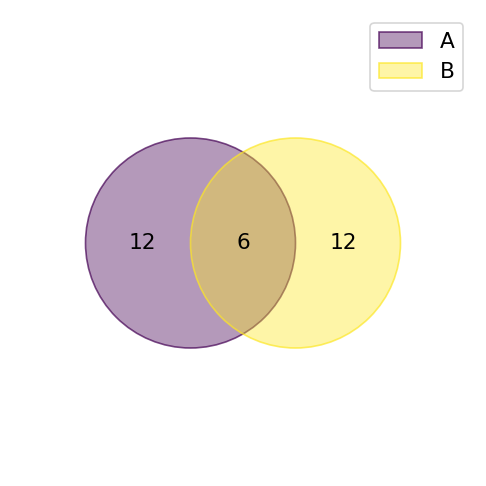

In [9]:
W = pd.DataFrame(W)
W.columns = ['A', 'B']
mutation_sets = {v: set(pd.DataFrame(W).index[pd.DataFrame(W)[v] == 1]) for v in pd.DataFrame(W).columns}
venn(mutation_sets, figsize=(5, 5))

In [10]:
# # Save simulated datasets for the cross validation

# import numpy as np
# import pandas as pd

# datasets = {
#     "disp1_missing_1_genetic_drift":  datasets["disp1_missing_1"],
#     "disp1_missing_6_genetic_drift":  datasets["disp1_missing_6"],
#     "disp1_missing_10_genetic_drift": datasets["disp1_missing_10"],
#     "disp1_missing_11_genetic_drift": datasets["disp1_missing_11"],

#     "disp2_missing_1_genetic_drift":  datasets["disp2_missing_1"],
#     "disp2_missing_6_genetic_drift":  datasets["disp2_missing_6"],
#     "disp2_missing_10_genetic_drift": datasets["disp2_missing_10"],
#     "disp2_missing_11_genetic_drift": datasets["disp2_missing_11"],

#     "disp3_missing_1_genetic_drift":  datasets["disp3_missing_1"],
#     "disp3_missing_6_genetic_drift":  datasets["disp3_missing_6"],
#     "disp3_missing_10_genetic_drift": datasets["disp3_missing_10"],
#     "disp3_missing_11_genetic_drift": datasets["disp3_missing_11"],
# }

# for name, data in datasets.items():
#     # works for DataFrames and for numpy arrays
#     df = data if isinstance(data, pd.DataFrame) else pd.DataFrame(np.asarray(data))
#     df.to_csv(f"simulated_data/{name}.csv", index=True)          # keeps the row labels (e.g. site names)
#     print(f"saved {name}.csv  shape={df.shape}  NaNs={int(df.isna().sum().sum())}")

In [11]:
# Cross validation results for already simulated data
simulated_data_cv = pd.read_csv('../results/cross_validation_results/simulations/cross_validation_summary_snv.csv')


In [12]:
SCENARIO = 'genetic_drift'
RANK = 2                                            # two variants under drift
TARGET_MISSING_FRACS = {0.0, 0.5, 0.9, 0.95}

selected_tiers = {t['name'] for t in QUALITY_TIERS if t['missing_frac'] in TARGET_MISSING_FRACS}
datasets_drift_subset = {tier: df for tier, df in datasets.items() if tier in selected_tiers}
cv_key = lambda tier: f"{tier}_{SCENARIO}"

cv = simulated_data_cv.dropna(subset=['mean_error'])
cv = cv[cv['n_variants'] == RANK]
opt_lambdas_drift = {}
for tier in datasets_drift_subset:
    g = cv[cv['location'] == cv_key(tier)]
    if g.empty:
        raise KeyError(f"no CV results at rank {RANK} for '{cv_key(tier)}'")
    b = g.loc[g['mean_error'].idxmin()]
    opt_lambdas_drift[tier] = dict(lambda_w=float(b['lambda_w']), lambda_h=float(b['lambda_h']),
                                   lambda_f=float(b['lambda_f']))
    print(f"{tier}: {opt_lambdas_drift[tier]}  (CV error {b['mean_error']:.4g})")

NMF_KWARGS_base = dict(masking_option=0, rank=RANK, rel_tol=1e-4, bandwidth=10.0, n_run=10,
                       random_state=42, n_jobs=-1, n_mu_steps=1)

nmf_results_drift_cv, nmf_results_drift_unreg = {}, {}
for tier, df in datasets_drift_subset.items():
    nmf_results_drift_cv[tier] = joint_soft_dynamics_nmf({'sim': df}, **NMF_KWARGS_base,
                                                         **opt_lambdas_drift[tier])
    nmf_results_drift_unreg[tier] = joint_soft_dynamics_nmf({'sim': df}, **NMF_KWARGS_base,
                                                            lambda_w=0, lambda_h=0, lambda_f=0)

disp1_missing_1: {'lambda_w': 0.5, 'lambda_h': 8.0, 'lambda_f': 0.0}  (CV error 0.01638)
disp1_missing_6: {'lambda_w': 0.8, 'lambda_h': 8.0, 'lambda_f': 0.01}  (CV error 0.01484)
disp1_missing_10: {'lambda_w': 0.2, 'lambda_h': 6.0, 'lambda_f': 4.0}  (CV error 0.01783)
disp1_missing_11: {'lambda_w': 0.4, 'lambda_h': 40.0, 'lambda_f': 60.0}  (CV error 0.01678)
disp2_missing_1: {'lambda_w': 5.0, 'lambda_h': 10.0, 'lambda_f': 0.0}  (CV error 0.01655)
disp2_missing_6: {'lambda_w': 1.0, 'lambda_h': 10.0, 'lambda_f': 0.0}  (CV error 0.01642)
disp2_missing_10: {'lambda_w': 0.2, 'lambda_h': 0.3, 'lambda_f': 40.0}  (CV error 0.01687)
disp2_missing_11: {'lambda_w': 0.0, 'lambda_h': 10.0, 'lambda_f': 0.1}  (CV error 0.01775)
disp3_missing_1: {'lambda_w': 3.0, 'lambda_h': 8.0, 'lambda_f': 0.0}  (CV error 0.02531)
disp3_missing_6: {'lambda_w': 2.0, 'lambda_h': 8.0, 'lambda_f': 0.0}  (CV error 0.02481)
disp3_missing_10: {'lambda_w': 1.0, 'lambda_h': 80.0, 'lambda_f': 80.0}  (CV error 0.02181)
disp3_m

In [13]:
def _match_components_to_ground_truth(W_binary, W_covspectrum,
                                        unassigned_threshold=0.5,
                                        unassigned_label='unassigned'):
    """
    Strict one-to-one matching via the Hungarian algorithm: each component
    is paired with at most one ground-truth variant and vice versa,
    maximizing the TOTAL summed Jaccard similarity across all pairs
    simultaneously -- unlike per-component argmax, this won't let two
    components both claim the same variant while a third gets none.
    NOTE! This is different from the real data predictions evalutation, where multiple components can be matched to the same variant.

    Handles rank != n_variants: linear_sum_assignment naturally produces
    only min(rank, n_variants) pairs; anything left over is genuinely
    unmatched, not just thresholded away.
    """
    all_muts = sorted(set(W_binary.index) | set(W_covspectrum.index))
    W_pred_final = W_binary.reindex(all_muts, fill_value=0)
    W_true_final = W_covspectrum.reindex(all_muts, fill_value=0)

    dist_matrix = cdist(W_pred_final.values.T, W_true_final.values.T, metric='jaccard')
    sim_matrix = 1 - dist_matrix
    sim_df = pd.DataFrame(sim_matrix, index=W_binary.columns, columns=W_covspectrum.columns)
    sim_df = sim_df.fillna(0.0)

    row_ind, col_ind = linear_sum_assignment(-sim_df.values)  # negate to maximize total similarity

    best_labels = [unassigned_label] * sim_df.shape[0]
    for i, j in zip(row_ind, col_ind):
        sim = sim_df.values[i, j]
        best_labels[i] = sim_df.columns[j] if sim >= unassigned_threshold else unassigned_label

    counts = {}
    new_labels = []
    for lbl in best_labels:
        counts[lbl] = counts.get(lbl, 0) + 1
        new_labels.append(lbl if counts[lbl] == 1 else f"{lbl} ({counts[lbl]})")

    return sim_df, new_labels, best_labels

(213, 2)


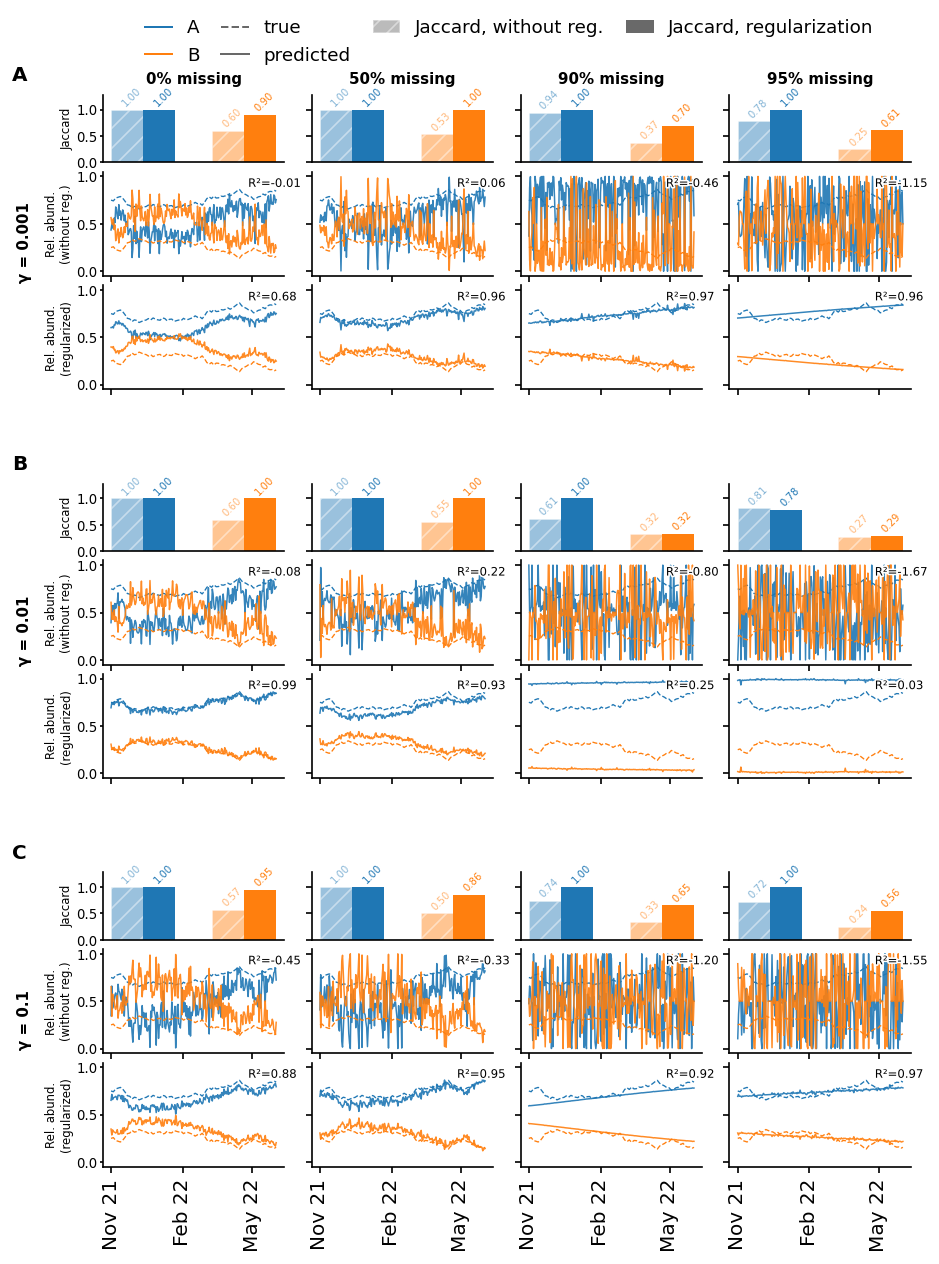

            tier  disp_level  missing_level  gamma  missing_frac  r2_10run  r2_100run  n_variants_matched_10run  n_variants_matched_100run  n_variants_total
 disp1_missing_1           1              1  0.001          0.00 -0.009405   0.679102                         2                          2                 2
 disp1_missing_6           1              6  0.001          0.50  0.056590   0.960899                         2                          2                 2
disp1_missing_10           1             10  0.001          0.90 -0.459754   0.968565                         2                          2                 2
disp1_missing_11           1             11  0.001          0.95 -1.146378   0.957733                         2                          2                 2
 disp2_missing_1           2              1  0.010          0.00 -0.079399   0.989996                         2                          2                 2
 disp2_missing_6           2              6  0.010        

In [14]:

def _r_squared(true_vals, pred_vals):
    true_vals = np.asarray(true_vals, dtype=float)
    pred_vals = np.asarray(pred_vals, dtype=float)
    ss_res = np.sum((true_vals - pred_vals) ** 2)
    ss_tot = np.sum((true_vals - true_vals.mean()) ** 2)
    return np.nan if ss_tot == 0 else 1 - ss_res / ss_tot


def _jaccard_per_variant(result, df, W_covspectrum, all_vars,
                          binarize_threshold, unassigned_threshold):
    """Runs the matching pipeline for one NMF result and returns
    (jaccard_per_variant, best_component_per_variant, label_to_k, H_norm)."""
    rank = result.W.shape[1]
    W_df = pd.DataFrame(result.W, index=list(df.index),
                         columns=[f'Component_{k}' for k in range(rank)])
    W_binary = (W_df >= binarize_threshold).astype(int)

    sim_df, new_labels, best_labels = _match_components_to_ground_truth(
        W_binary, W_covspectrum, unassigned_threshold=unassigned_threshold)
    sim_df.index = new_labels
    label_to_k = {label: k for k, label in enumerate(new_labels)}

    gt_to_pred_labels = {}
    for pred_label, gt_label in zip(new_labels, best_labels):
        gt_to_pred_labels.setdefault(gt_label, []).append(pred_label)

    jaccard_per_variant, best_component_per_variant = {}, {}
    for v in all_vars:
        candidates = gt_to_pred_labels.get(v, [])
        if not candidates:
            jaccard_per_variant[v] = np.nan
            best_component_per_variant[v] = None
            continue
        scores = {pl: sim_df.loc[pl, v] for pl in candidates}
        best_pl = max(scores, key=scores.get)
        jaccard_per_variant[v] = scores[best_pl]
        best_component_per_variant[v] = best_pl

    H_norm = result.H['sim'] / result.H['sim'].sum(axis=0, keepdims=True)
    return jaccard_per_variant, best_component_per_variant, label_to_k, H_norm


def evaluate_and_plot_grid_nature(nmf_results_10, nmf_results_100, datasets,
                                   W_covspectrum, abundance_matrix,
                                   tier_config=None,
                                   binarize_threshold=0.5, unassigned_threshold=0.0,
                                   colors=None, fig_width_mm=183, cell_aspect=1.9):
    all_vars = list(W_covspectrum.columns)
    bar_colors = [colors.get(v, f'C{i}') if colors else f'C{i}' for i, v in enumerate(all_vars)]
    variant_labels = ["A", "B"]
    tier_grid = {}
    for tier in nmf_results_100:
        m = re.match(r'disp(\d+)_missing_(\d+)', tier)
        if not m:
            raise ValueError(f"Tier name '{tier}' doesn't match 'dispD_missing_M'.")
        tier_grid[(int(m.group(1)), int(m.group(2)))] = tier

    disp_levels = sorted({d for d, _ in tier_grid})
    missing_levels = sorted({mm for _, mm in tier_grid})
    n_rows, n_cols = len(disp_levels), len(missing_levels)

    row_headers = [f'disp {d}' for d in disp_levels]
    col_headers = [f'missing {mm}' for mm in missing_levels]
    gamma_by_disp, missfrac_by_col = {}, {}
    if tier_config is not None:
        cfg_by_name = {t['name']: t for t in tier_config}
        for (d, mm), name in tier_grid.items():
            cfg = cfg_by_name.get(name)
            if cfg is not None:
                gamma_by_disp[d] = cfg['gamma']
                missfrac_by_col[mm] = cfg['missing_frac']
        row_headers = [f'\u03b3 = {gamma_by_disp[d]:g}' for d in disp_levels]
        col_headers = [f'{missfrac_by_col[mm]*100:.0f}% missing' for mm in missing_levels]

    fig_w_in = fig_width_mm / 25.4
    fig_h_in = fig_w_in / n_cols * n_rows * cell_aspect
    fig = plt.figure(figsize=(fig_w_in, fig_h_in))
    outer = GridSpec(n_rows, n_cols, figure=fig,
                      left=0.06, right=0.995, top=0.92, bottom=0.05,
                      hspace=0.32, wspace=0.15)

    date_locator = mdates.MonthLocator(interval=3)
    date_formatter = mdates.DateFormatter('%b %y')
    r2_records = []
    bar_width = 0.32
    x = np.arange(len(all_vars))

    def _plot_abundance_panel(ax, dates, best_component_per_variant, label_to_k, H_norm):
        true_all, pred_all = [], []
        for i, v in enumerate(all_vars):
            ax.plot(dates, abundance_matrix[:, i], color=bar_colors[i],
                    linestyle='--', linewidth=0.8)
            best_pl = best_component_per_variant[v]
            if best_pl is not None:
                pred_vals = H_norm[label_to_k[best_pl]]
                ax.plot(dates, pred_vals, color=bar_colors[i],
                        linestyle='-', linewidth=0.9, alpha=0.9)
                true_all.append(abundance_matrix[:, i])
                pred_all.append(pred_vals)
        ax.set_ylim(-0.05, 1.05)
        ax.set_yticks([0, 0.5, 1])
        ax.spines[['top', 'right']].set_visible(False)
        r2 = np.nan
        n_matched = len(true_all)
        if true_all:
            r2 = _r_squared(np.concatenate(true_all), np.concatenate(pred_all))
            r2_text = ax.text(0.8, 0.95, f'R\u00b2={r2:.2f}', transform=ax.transAxes,
                               ha='left', va='top', fontsize=7, color='black', zorder=10)
            r2_text.set_path_effects([pe.withStroke(linewidth=2, foreground='white')])
        return r2, n_matched

    for r, disp_i in enumerate(disp_levels):
        for c, missing_j in enumerate(missing_levels):
            tier = tier_grid[(disp_i, missing_j)]
            df = datasets[tier]
            dates = pd.DatetimeIndex(df.columns)

            jacc_10, best_component_10, label_to_k_10, H_norm_10 = _jaccard_per_variant(
                nmf_results_10[tier], df, W_covspectrum, all_vars,
                binarize_threshold, unassigned_threshold)
            jacc_100, best_component_100, label_to_k_100, H_norm_100 = _jaccard_per_variant(
                nmf_results_100[tier], df, W_covspectrum, all_vars,
                binarize_threshold, unassigned_threshold)

            inner = outer[r, c].subgridspec(3, 1, height_ratios=[0.55, 0.85, 0.85], hspace=0.1)
            ax_bar = fig.add_subplot(inner[0])
            ax_ab10 = fig.add_subplot(inner[1])
            ax_ab100 = fig.add_subplot(inner[2])

            ax_bar.bar(x - bar_width / 2, [jacc_10[v] for v in all_vars],
                       width=bar_width, color=bar_colors, alpha=0.45,
                       hatch='//', edgecolor='white', linewidth=0.3)
            ax_bar.bar(x + bar_width / 2, [jacc_100[v] for v in all_vars],
                       width=bar_width, color=bar_colors, linewidth=0)
            ax_bar.set_ylim(0, 1.28)
            ax_bar.set_yticks([0, 0.5, 1])
            ax_bar.set_xticks([])
            ax_bar.spines[['top', 'right']].set_visible(False)
            if c != 0:
                ax_bar.set_yticklabels([])
            for i, v in enumerate(all_vars):
                val10 = jacc_10[v]
                if not np.isnan(val10):
                    ax_bar.text(x[i] - bar_width / 2, val10 + 0.03, f'{val10:.2f}',
                                ha='left', va='bottom', fontsize=6, color=bar_colors[i],
                                alpha=0.55, rotation=45, rotation_mode='anchor')
                val100 = jacc_100[v]
                if not np.isnan(val100):
                    ax_bar.text(x[i] + bar_width / 2, val100 + 0.03, f'{val100:.2f}',
                                ha='left', va='bottom', fontsize=6, color=bar_colors[i],
                                rotation=45, rotation_mode='anchor')

            r2_10, n_matched_10 = _plot_abundance_panel(
                ax_ab10, dates, best_component_10, label_to_k_10, H_norm_10)
            r2_100, n_matched_100 = _plot_abundance_panel(
                ax_ab100, dates, best_component_100, label_to_k_100, H_norm_100)

            ax_ab10.xaxis.set_major_locator(date_locator)
            ax_ab10.set_xticklabels([])
            ax_ab100.xaxis.set_major_locator(date_locator)
            ax_ab100.xaxis.set_major_formatter(date_formatter)
            ax_ab100.tick_params(axis='x', rotation=90)
            if r != n_rows - 1:
                ax_ab100.set_xticklabels([])
            if c != 0:
                ax_ab10.set_yticklabels([])
                ax_ab100.set_yticklabels([])

            r2_records.append(dict(
                tier=tier, disp_level=disp_i, missing_level=missing_j,
                gamma=gamma_by_disp.get(disp_i), missing_frac=missfrac_by_col.get(missing_j),
                r2_10run=r2_10, r2_100run=r2_100,
                n_variants_matched_10run=n_matched_10, n_variants_matched_100run=n_matched_100,
                n_variants_total=len(all_vars),
            ))

            if c == 0:
                ax_bar.set_ylabel('Jaccard', labelpad=2,  fontsize=7)
                ax_ab10.set_ylabel('Rel. abund.\n(without reg.)', labelpad=2, fontsize=7)
                ax_ab100.set_ylabel('Rel. abund.\n(regularized)', labelpad=2, fontsize=7)
                for a in (ax_bar, ax_ab10, ax_ab100):
                    a.tick_params(axis='y', labelsize=8, length=2, pad=1)
            if r == 0:
                ax_bar.set_title(col_headers[c], fontsize=9, pad=7, fontweight='bold')

        pos = outer[r, 0].get_position(fig)
        fig.text(-0.03, pos.y0 + pos.height / 2, row_headers[r],
                  rotation=90, va='center', ha='center', fontsize=9, fontweight='bold')
        fig.text(-0.045, pos.y1 + 0.008, chr(65 + r),
                  fontsize=12, fontweight='bold', ha='left', va='bottom')


    legend_handles = (

        [plt.Line2D([0], [0], color=bar_colors[i], lw=1.2, label=v) for i, v in enumerate(variant_labels)]
        + [plt.Line2D([0], [0], color='dimgray', lw=1.2, linestyle='--', label='true'),
           plt.Line2D([0], [0], color='dimgray', lw=1.2, linestyle='-', label='predicted'),
           plt.Rectangle((0, 0), 1, 1, facecolor='dimgray', alpha=0.45, hatch='//',
                          edgecolor='white', label='Jaccard, without reg.'),
           plt.Rectangle((0, 0), 1, 1, facecolor='dimgray', label='Jaccard, regularization')]
    )

    fig.legend(handles=legend_handles, loc='upper center', ncol=4,
               frameon=False, bbox_to_anchor=(0.53, 0.995), handlelength=1.5, columnspacing=1.2)

    r2_df = pd.DataFrame(r2_records)
    return fig, r2_df

abund = abundance_matrix
if isinstance(abund, pd.DataFrame):
    if set(X.columns) <= set(abund.index):            # rows are variants -> same order as X
        abund = abund.loc[list(X.columns)]
    elif set(X.columns) <= set(abund.columns):        # columns are variants
        abund = abund[list(X.columns)].T
    abund = abund.to_numpy(dtype=float)               # now (variants, time)
else:
    abund = np.asarray(abund, dtype=float)

if abund.shape[0] == len(X.columns):                  # (variants, time) -> (time, variants)
    abund = abund.T
print(abund.shape)                                    # must be (213, 2)

n_time = datasets[next(iter(datasets))].shape[1]
assert abund.shape == (n_time, len(X.columns)), abund.shape




fig, r2_table_drift = evaluate_and_plot_grid_nature(
    nmf_results_drift_unreg, nmf_results_drift_cv, datasets,
    W_covspectrum=X, abundance_matrix=abund, tier_config=QUALITY_TIERS)
fig.savefig('../results/simulated_data/fig_nmf_grid_simulation_drift.pdf', bbox_inches='tight')
plt.show()
print(r2_table_drift.to_string(index=False))